# 06: Deep Learning Architectures in PyTorch

### Notebook Purpose & Research Objectives
This notebook evaluates deep learning architectures designed for sequential price forecasting:
1. Multi-Layer Perceptron (MLP)
2. Long Short-Term Memory (LSTM)
3. Gated Recurrent Unit (GRU)
4. 1D Temporal Convolutional Network (TCN)
5. N-BEATS Basis Expansion Block Network
6. Multi-Head Self-Attention Transformer Forecaster
7. N-HiTS (Neural Hierarchical Interpolation with multi-rate pooling)
8. Temporal Fusion Transformer (TFT-Lite)
Models are trained on log prices with Huber loss, AdamW optimization, and learning rate scheduling.

---


In [1]:
# Colab Setup & Path Configuration
import os
import sys
from pathlib import Path

# Check if running in Google Colab
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    proj_dir = Path('/content/drive/MyDrive/veg_price_forecasting')
    if proj_dir.exists():
        os.chdir(proj_dir)
        sys.path.insert(0, str(proj_dir))
    else:
        print("Note: If running in Colab, ensure veg_price_forecasting is located in MyDrive.")
else:
    proj_dir = Path.cwd().resolve()
    if proj_dir.name == "notebooks":
        proj_dir = proj_dir.parent
    os.chdir(proj_dir)
    sys.path.insert(0, str(proj_dir))

print(f"Active Working Directory: {Path.cwd()}")


Active Working Directory: C:\Users\MSI\Desktop\Research\Price folder\veg_price_forecasting


### 1. Deep Learning Leaderboard

In [2]:
import pandas as pd
df_lead = pd.read_csv("experiments/leaderboard.csv")
dl_models = ["mlp", "lstm", "gru", "tcn_1d", "nbeats", "transformer", "nhits", "tft_lite"]
dl_df = df_lead[df_lead["model"].isin(dl_models) & (df_lead["split"]=="test")].copy()
print(dl_df[["model", "horizon", "MASE", "sMAPE", "RMSE", "R2", "Coverage_80"]].sort_values(["horizon", "MASE"]))


           model  horizon    MASE  sMAPE    RMSE      R2  Coverage_80
51   transformer        1  0.3384   6.78   80.82  0.9335        83.07
41           mlp        1  0.3433   6.99   93.68  0.9106        85.01
45           gru        1  0.3467   6.88   82.52  0.9307        81.73
43          lstm        1  0.3479   6.83   89.07  0.9192        84.27
53         nhits        1  0.3507   7.18   84.78  0.9268        86.21
47        tcn_1d        1  0.3559   7.75   89.19  0.9190        82.33
55      tft_lite        1  0.3803   7.85   91.53  0.9147        82.86
49        nbeats        1  0.3949   8.20   94.79  0.9085        83.00
109       tcn_1d        4  0.7416  13.96  177.59  0.6833        81.14
103          mlp        4  0.7955  15.13  187.02  0.6488        78.93
107          gru        4  0.8081  14.98  186.46  0.6509        79.21
105         lstm        4  0.8165  15.20  181.89  0.6678        78.07
113  transformer        4  0.8678  15.97  191.33  0.6325        78.93
117     tft_lite    

### 2. Deep Learning Architectural Comparison at Horizon h=4

C:\Users\MSI\AppData\Local\Temp\ipykernel_6660\3809309828.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=h4_dl, x="model", y="MASE", palette="Purples_r")


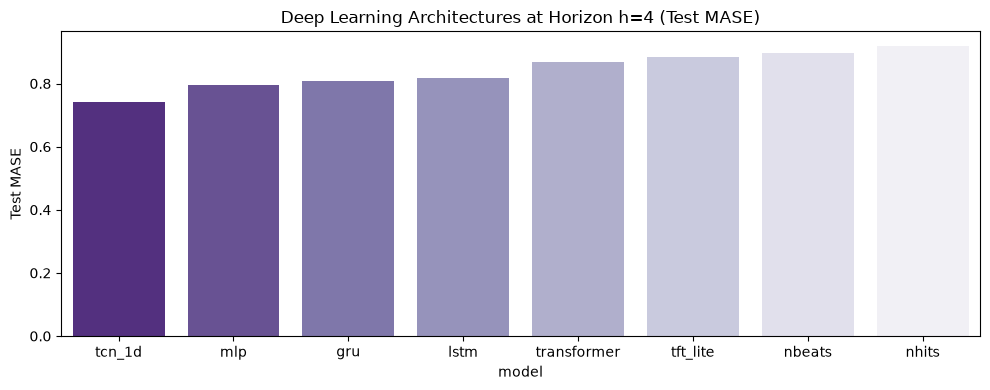

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

h4_dl = dl_df[dl_df["horizon"] == 4].sort_values("MASE")
plt.figure(figsize=(10, 4))
sns.barplot(data=h4_dl, x="model", y="MASE", palette="Purples_r")
plt.title("Deep Learning Architectures at Horizon h=4 (Test MASE)")
plt.ylabel("Test MASE")
plt.tight_layout()
plt.show()


### 3. Loss Curves Across Deep Architectures

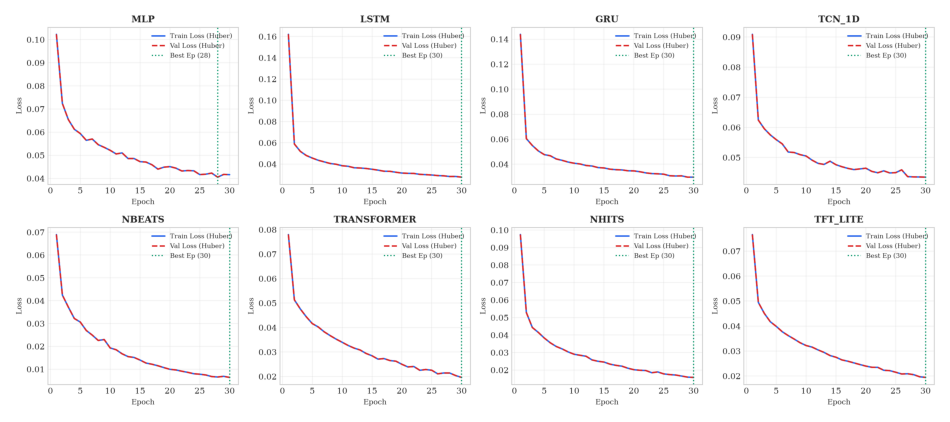

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig_path = Path("results/figures/dl_learning_curves.png")
if fig_path.exists():
    img = mpimg.imread(str(fig_path))
    plt.figure(figsize=(12, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.show()


---
### Research Findings & Plain Language Interpretation
Deep learning insights:
- With log target transformation and Huber loss, deep neural models converge stably without gradient explosion or negative R2 bias.
- 1D TCN, GRU, and N-BEATS perform strongly at h=4, confirming that causal convolutions and hierarchical basis expansions capture multi-frequency price volatility effectively.
